# Nonradiative Transition Rates Using the One-Dimensional Configurational Coordinate Diagram

In [1]:
%matplotlib widget
import numpy as np
from scipy import constants
import matplotlib.pyplot as plt
import re
from pathlib import Path

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'

from pypl.config_coord_1d_solver import config_coord_1d_solver
from pypl.utils import *
import os

path = os.getcwd()
os.chdir(path)

In [2]:
def read_positions(path: str):
    """
    Read a QE pw.x input file from `path` and return:
      - symbols: (nat,) numpy array of strings
      - xyz_A:  (nat, 3) numpy array of Cartesian coordinates in Angstrom
      - cell_A: (3, 3) numpy array of cell vectors in Angstrom (rows are a1,a2,a3)

    Assumes the file contains:
      - ibrav = 0
      - CELL_PARAMETERS angstrom
      - ATOMIC_POSITIONS crystal
    """

    def strip_comments(s: str) -> str:
        return s.split("!")[0].split("#")[0].strip()

    def fnum(x: str) -> float:
        # supports Fortran D exponents like 1.0D-8
        return float(re.sub(r"[dD]", "e", x.strip().rstrip(",")))

    def find_line_idx(lines, startswith):
        target = startswith.lower()
        for i, raw in enumerate(lines):
            if strip_comments(raw).lower().startswith(target):
                return i
        return None

    def parse_nat(lines):
        in_system = False
        for raw in lines:
            line = strip_comments(raw)
            if re.match(r"^\s*&system\b", line, re.IGNORECASE):
                in_system = True
            if in_system:
                m = re.search(r"\bnat\s*=\s*(\d+)", line, re.IGNORECASE)
                if m:
                    return int(m.group(1))
                if line.strip().startswith("/"):
                    in_system = False
        raise ValueError("Could not find nat in &system namelist.")

    text = Path(path).read_text()
    lines = text.splitlines()

    nat = parse_nat(lines)

    i_cell = find_line_idx(lines, "cell_parameters")
    if i_cell is None:
        raise ValueError("CELL_PARAMETERS not found (expects ibrav=0 with explicit cell).")

    cell_header = strip_comments(lines[i_cell]).lower()
    if "angstrom" not in cell_header:
        raise ValueError(f"Expected CELL_PARAMETERS angstrom, got: {lines[i_cell]}")

    a1 = np.array([fnum(x) for x in strip_comments(lines[i_cell + 1]).split()[:3]], dtype=float)
    a2 = np.array([fnum(x) for x in strip_comments(lines[i_cell + 2]).split()[:3]], dtype=float)
    a3 = np.array([fnum(x) for x in strip_comments(lines[i_cell + 3]).split()[:3]], dtype=float)
    cell_A = np.vstack([a1, a2, a3])  # rows are lattice vectors

    i_pos = find_line_idx(lines, "atomic_positions")
    if i_pos is None:
        raise ValueError("ATOMIC_POSITIONS not found.")

    pos_header = strip_comments(lines[i_pos]).lower()
    if "crystal" not in pos_header:
        raise ValueError(f"Expected ATOMIC_POSITIONS crystal, got: {lines[i_pos]}")

    symbols = np.empty(nat, dtype="U4")
    frac = np.empty((nat, 3), dtype=float)

    for k in range(nat):
        raw = strip_comments(lines[i_pos + 1 + k])
        parts = raw.split()
        if len(parts) < 4:
            raise ValueError(f"Bad ATOMIC_POSITIONS line at #{k+1}: {lines[i_pos + 1 + k]}")
        symbols[k] = parts[0]
        frac[k, :] = [fnum(parts[1]), fnum(parts[2]), fnum(parts[3])]

    # Cartesian Å: r = f1*a1 + f2*a2 + f3*a3
    xyz_A = frac @ cell_A

    return symbols, xyz_A, cell_A


def extract_NAC(file_path, section_title, n_atoms=0):
    """
    Extract exactly n_atoms NAC vectors from the given section.
    Skips blank lines and header separators.
    """
    
    if not isinstance(n_atoms, int) or n_atoms <= 0:
        raise ValueError("Parameter 'n_atoms' must be a positive integer greater than zero.")

    NAC = []
    with open(file_path, "r") as infile:
        lines = infile.readlines()

    capture = False
    for line in lines:
        if section_title in line:
            capture = True
            continue

        if capture and len(NAC) < n_atoms:
            parts = line.strip().split()
            if not parts or parts[0] != "atom":
                continue  # skip empty or non-data lines

            # atom_idx = int(parts[1])   # after "atom"
            # atom_type = int(parts[3])  # after "type"
            fx, fy, fz = map(float, parts[6:9])
            NAC.append([fx, fy, fz])

        if len(NAC) == n_atoms:
            break

    return np.array(NAC)

In [3]:
N_atoms = 398
Ry_to_eV = 13.6057039761
Bohr_to_A = 0.529177
C_amu = 12.01 # Carbon atom mass in amu
Si_amu = 28.085 # Silicon atom mass in amu
masses = np.ones(N_atoms)
masses[:N_atoms//2] = Si_amu
masses[N_atoms//2:] = C_amu
factor = Ry_to_eV/(Bohr_to_A*np.sqrt(masses))
#
file_3A2_coord = "3A2_coord.txt"
file_3E_coord = "3E_coord.txt"
coord_3E = read_positions(file_3E_coord)[1] 
coord_3A2 = read_positions(file_3A2_coord)[1]
DeltaR = coord_3A2 - coord_3E 
DeltaQ = np.linalg.norm( np.einsum('ij,i->ij', DeltaR, np.sqrt(masses) ) )
print(r"Q : %.2f amu^1/2 A"%( DeltaQ ))
OneD_mode = DeltaR / np.linalg.norm( DeltaR )
#
NAC_file = "/home/svillani/WorkInProgress/NRTR/SiC/SiC_nonrad/400_atoms/DDH/3E/wbse.out"
NAC_vec  = extract_NAC(NAC_file, "geNAC corrected", N_atoms)
#
DeltaE = 1.351 / Ry_to_eV # Ry
#
M_if = np.einsum('ij,ij->', NAC_vec, np.einsum('ij,i->ij', OneD_mode, factor) ) * DeltaE 
print(r"M_if: %.3e eV amu^-1/2 A^-1"%(M_if))

Q : 0.78 amu^1/2 A
M_if: 2.970e-04 eV amu^-1/2 A^-1


In [4]:
import numpy as np
from scipy import constants
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'

from pypl.config_coord_1d_solver import config_coord_1d_solver
from pypl.utils import *
import os

path = os.getcwd()
os.chdir(path)

# meV
freq_ini = 36.41 # meV
freq_fin = 38.70 # meV

# amu^{1/2} Å
delta_q = 0.78
# dE (meV)
dE = 1351 
# electron-phonon coupling (eV / amu^{1/2} / \AA)
M_if = 2.970e-04 # f with TDDFT-NACs DDH 
# energy range for plot
ene_range = [-300, 2200]
# resolution
resol = 25001
# broadening (meV)
sigma = [64, 64]
# temperature (K)
temp = 78
#
nstates_i = 200
nstates_f = 200

We compute the Franck–Condon (FC) integrals as well as the integrals with the coordinate $Q$ in between and the spectral functions

In [5]:
nv_ccd_pl = config_coord_1d_solver(freq_ini, freq_fin, delta_q)
nv_ccd_pl.compute_franck_condon_integrals(ni=nstates_i, nf=nstates_f)
nv_ccd_pl.compute_q_integrals_right()

energy_axis, ht_lineshape = nv_ccd_pl.bulid_ht_lsp(
    reldtdmdq=1.0,
    fc_ints_q=nv_ccd_pl.fc_ints_q_right,
    eneaxis=np.linspace(ene_range[0], ene_range[1], resol),
    temp=temp,
    sigma=sigma,
    zpl_lorentzian=False
)

To plot nonradiative line-shape, uncomment the lines in the block 

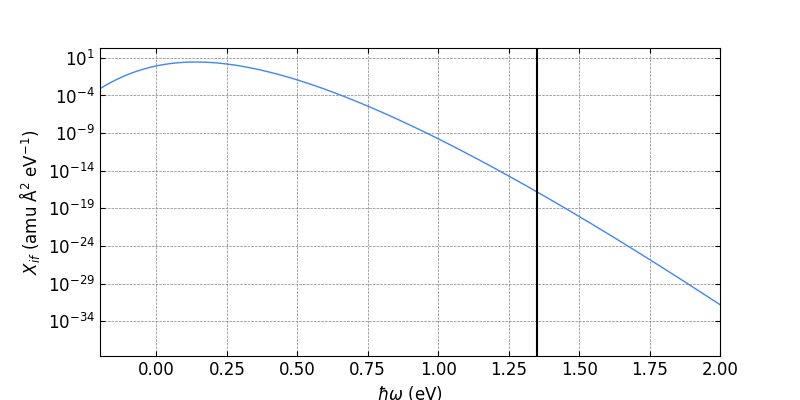

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))

ax.plot(energy_axis * 1e-3, ht_lineshape * 1e3,
        color=blue, linewidth=1, linestyle='-')

# ---------------------------------------------
# uncomment this to save/plot the 1D lineshape function F(\Delta) 
# np.savez("SiC_triplets_effmode_T78K",
#          x=energy_axis, 
#          y= 2 * np.pi / constants.hbar * M_if**2 * ht_lineshape * 1e3 * constants.eV
#         )
# ax.plot(energy_axis * 1e-3, 2 * np.pi / constants.hbar * M_if**2 * ht_lineshape * 1e3 * constants.eV, 
#         color=blue, linewidth=1, linestyle='-')
# ---------------------------------------------

ax.axvline(x=dE * 1e-3, ymin=0, ymax=1, color='k')

ax.set_xlim((-0.2, 2.0))

ax.grid(color='gray', linestyle='--', linewidth=0.5)

ax.tick_params(direction='in')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.set_xlabel(r'$\hbar\omega$ (eV)')
ax.set_ylabel(r'$X_{if}$ (amu Å$^2$ eV$^{-1}$)')
ax.set_yscale('log')

plt.show()

In [7]:
index = np.where(energy_axis * 1e-3 - dE * 1e-3==0.0)[0]
Xif = ht_lineshape[index] * 1e3
print(Xif)

[1.53955351e-17]


In [8]:
# degeneracy factor
g = 1

nv_ic_rate = 2 * np.pi / constants.hbar * g * M_if**2 * Xif * constants.eV * 1e-6
print("%.2e"%nv_ic_rate[0], ' MHz')

1.30e-14  MHz
